In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

scaled = pd.read_csv("data/processed/week09/zip_clustering_scaled.csv", dtype={"Postal Code": "string"})
profiles = pd.read_csv("data/processed/week09/zip_clustering_profiles.csv", dtype={"Postal Code": "string"})

features = ["Log_EV_Count", "BEV_Percentage", "Avg_Model_Year"]

print("Scaled table:", scaled.shape, "| Profiles table:", profiles.shape)
print("Same ZIP codes in both:", set(scaled["Postal Code"]) == set(profiles["Postal Code"]))
print("Missing values in features:", int(scaled[features].isna().sum().sum()))
print(scaled[features].describe().round(2))

Scaled table: (249, 4) | Profiles table: (249, 11)
Same ZIP codes in both: True
Missing values in features: 0
       Log_EV_Count  BEV_Percentage  Avg_Model_Year
count        249.00          249.00          249.00
mean           0.00            0.00            0.00
std            1.00            1.00            1.00
min           -1.87           -5.74           -2.81
25%           -0.83           -0.51           -0.55
50%           -0.02            0.06            0.04
75%            0.73            0.70            0.60
max            2.68            2.86            3.92


 k  inertia  silhouette  smallest_cluster  largest_cluster
 2    509.8       0.287               106              143
 3    408.9       0.282                67               99
 4    341.9       0.272                52               81
 5    279.4       0.296                24               87
 6    249.0       0.300                 2               86


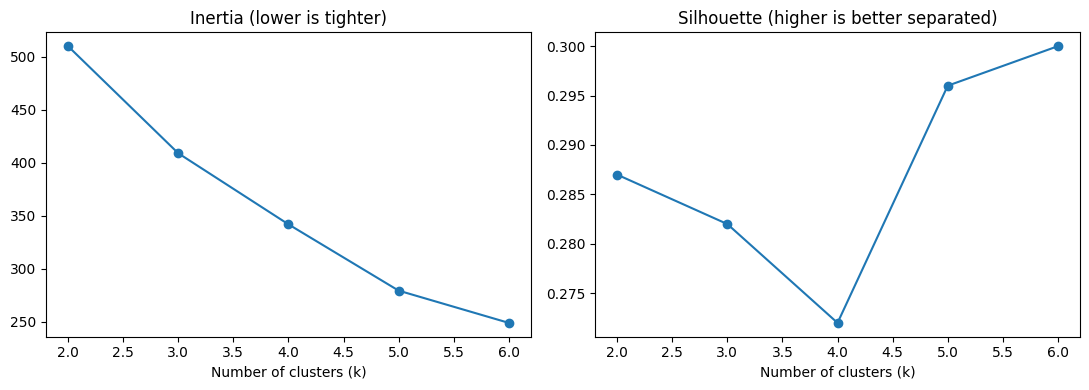

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = scaled[features].values

rows = []
models = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X)
    models[k] = (km, labels)
    sizes = np.bincount(labels)
    rows.append({
        "k": k,
        "inertia": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels), 3),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(results["k"], results["inertia"], marker="o")
ax[0].set_title("Inertia (lower is tighter)")
ax[0].set_xlabel("Number of clusters (k)")
ax[1].plot(results["k"], results["silhouette"], marker="o")
ax[1].set_title("Silhouette (higher is better separated)")
ax[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

In [3]:
prof = profiles.set_index("Postal Code").loc[scaled["Postal Code"]].reset_index()

def describe(k):
    labels = models[k][1]
    tmp = prof.assign(cluster=labels)
    return tmp.groupby("cluster").agg(
        ZIP_codes=("Postal Code", "count"),
        Median_vehicles=("EV_Count", "median"),
        Avg_BEV_pct=("BEV_Percentage", "mean"),
        Avg_model_year=("Avg_Model_Year", "mean"),
    ).round(1)

for k in (2, 5):
    print("k =", k)
    print(describe(k))
    print()

labels6 = models[6][1]
tiny = int(np.bincount(labels6).argmin())
print("k = 6, smallest cluster:")
print(prof.assign(cluster=labels6).query("cluster == @tiny")[["Postal Code", "EV_Count", "BEV_Percentage", "Avg_Model_Year"]])

k = 2
         ZIP_codes  Median_vehicles  Avg_BEV_pct  Avg_model_year
cluster                                                         
0              143             89.0         75.6          2022.0
1              106            267.0         83.1          2022.5

k = 5
         ZIP_codes  Median_vehicles  Avg_BEV_pct  Avg_model_year
cluster                                                         
0               39             71.0         76.2          2021.4
1               87            189.0         77.7          2022.2
2               46             58.0         82.5          2022.5
3               24             74.5         65.8          2022.3
4               53            339.0         85.4          2022.7

k = 6, smallest cluster:
   Postal Code  EV_Count  BEV_Percentage  Avg_Model_Year
39       98057       162       39.506173     2023.561728
80       98188       308       55.519481     2023.133117


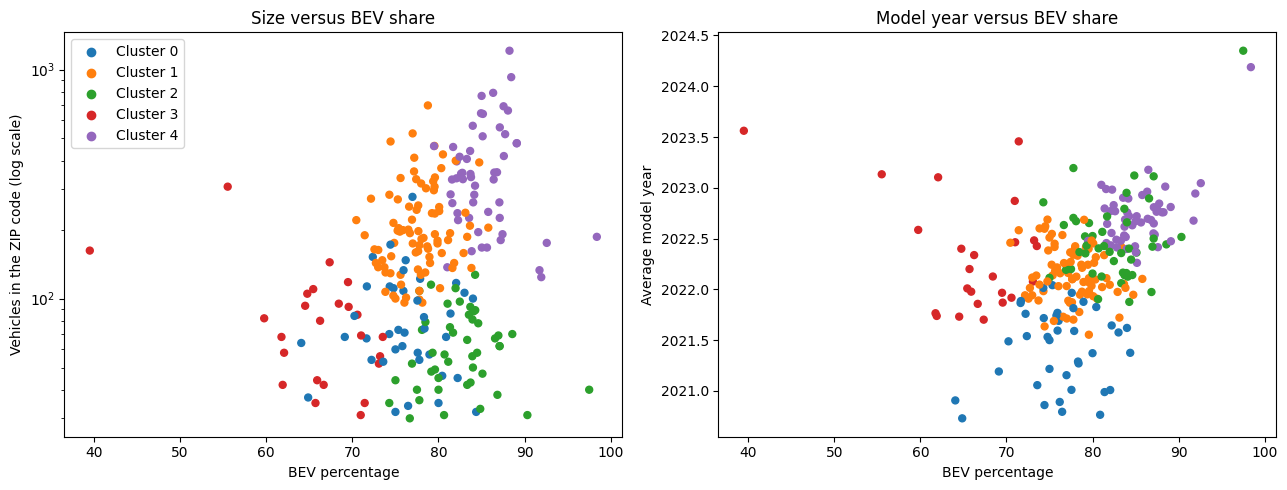

Saved 249 ZIP codes to data/processed/mining/zip_clusters_k5.csv


In [4]:
from pathlib import Path

K = 5
labels = models[K][1]
final = prof.assign(cluster=labels)
colors = [plt.cm.tab10(c) for c in labels]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(final["BEV_Percentage"], final["EV_Count"], color=colors, s=25)
ax[0].set_yscale("log")
ax[0].set_xlabel("BEV percentage")
ax[0].set_ylabel("Vehicles in the ZIP code (log scale)")
ax[0].set_title("Size versus BEV share")
ax[1].scatter(final["BEV_Percentage"], final["Avg_Model_Year"], color=colors, s=25)
ax[1].set_xlabel("BEV percentage")
ax[1].set_ylabel("Average model year")
ax[1].set_title("Model year versus BEV share")
for c in range(K):
    ax[0].scatter([], [], color=plt.cm.tab10(c), label="Cluster " + str(c))
ax[0].legend()
plt.tight_layout()
plt.show()

out = Path("data/processed/mining")
out.mkdir(parents=True, exist_ok=True)
final[["Postal Code", "cluster"]].to_csv(out / "zip_clusters_k5.csv", index=False)
print("Saved", len(final), "ZIP codes to", out / "zip_clusters_k5.csv")

In [5]:
from sklearn.metrics import adjusted_rand_score

base = models[5][1]
scores = []
for seed in range(20):
    lab = KMeans(n_clusters=5, n_init=20, random_state=seed).fit_predict(X)
    scores.append(adjusted_rand_score(base, lab))

print("Agreement with the seed-42 result across 20 other seeds (1.0 = identical):")
print("  lowest:", round(min(scores), 3), "| average:", round(float(np.mean(scores)), 3))

Agreement with the seed-42 result across 20 other seeds (1.0 = identical):
  lowest: 0.908 | average: 0.937


# K-means clustering of ZIP code fleet profiles

## What we did
We grouped Washington ZIP codes that have similar electric vehicle fleets. We kept the 249 ZIP codes with at least 30 vehicles in our sample. For each one we used three numbers: the log of the vehicle count, the percent of battery electric vehicles (BEV), and the average model year. We standardized them so they are on the same scale. Then we ran k-means with straight-line (Euclidean) distance, trying 2 to 6 clusters with 20 random starts each and a fixed seed of 42.

## How we picked the number of clusters
- The silhouette score was low for every choice, between 0.272 and 0.300. That means the groups are not sharply separated.
- Inertia went down smoothly with no clear bend.
- With 6 clusters the score was highest (0.300), but the smallest cluster had only 2 ZIP codes (98057 and 98188, both with very low BEV shares). So that score comes from two unusual ZIP codes, not a real group.
- We chose 5 clusters. Its score (0.296) is almost the best, it has no tiny cluster, and we can describe each group. Two clusters is a simpler option that mostly splits big ZIP codes from small ones.

## The five groups
- Cluster 4 (53 ZIP codes): big ZIP codes, median 339 vehicles, 85.4% BEV, average model year 2022.7.
- Cluster 1 (87): medium size, median 189 vehicles, 77.7% BEV, 2022.2.
- Cluster 2 (46): smaller, median 58 vehicles, 82.5% BEV, 2022.5.
- Cluster 0 (39): smaller, median 71 vehicles, 76.2% BEV, the oldest fleets at 2021.4.
- Cluster 3 (24): the lowest BEV share at 65.8%, so more plug-in hybrids, median 74.5 vehicles, 2022.3.

## Is it stable?
We reran the clustering with 20 other random seeds and compared each result with the seed-42 one. The agreement score (adjusted Rand index) was 0.908 at the lowest and 0.937 on average, where 1.0 means identical. So the grouping does not change much with the random start.

## Limits
- The groups overlap and the silhouette is low, so these are rough profiles, not clearly separate types.
- Average model year only differs by about 1.3 years across the clusters.
- ZIP codes with fewer than 30 vehicles are left out.
- We did not use electric range because most of it is missing.
- These are patterns in a sample. They do not explain why the differences exist.